# 07 · Portfolio construction

* Sleeves are scaled to 6% ex-ante volatility each (trailing 63 days at current weights).
* Per-name cap 7.5% of NAV; gross cap 250%; at most 10% of a stock's 60-day median daily value.
* Residual market beta hedged with SPY; drawdown brake halves risk after a 15% drawdown.
* Costs: half-spread by liquidity tier plus square-root impact; borrow 0.5%-15% a year by tier.
* Targets set at the close of *t* are traded at the close of *t+1*.

In [1]:
import json, warnings
import pandas as pd, matplotlib.pyplot as plt
from IPython.display import Markdown, display
from shiplab import charts
from shiplab.config import DATA
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 3, "display.width", 140)
R = DATA / "results"
perf = pd.read_csv(R / "performance_by_period.csv")
strat = pd.read_parquet(R / "strategy_returns.parquet")
bench = pd.read_parquet(R / "benchmark_returns.parquet")
dsr = json.load(open(R / "deflated_sharpe.json"))
def row(period, series="Strategy"):
    return perf[(perf.period == period) & (perf.series == series)].iloc[0]

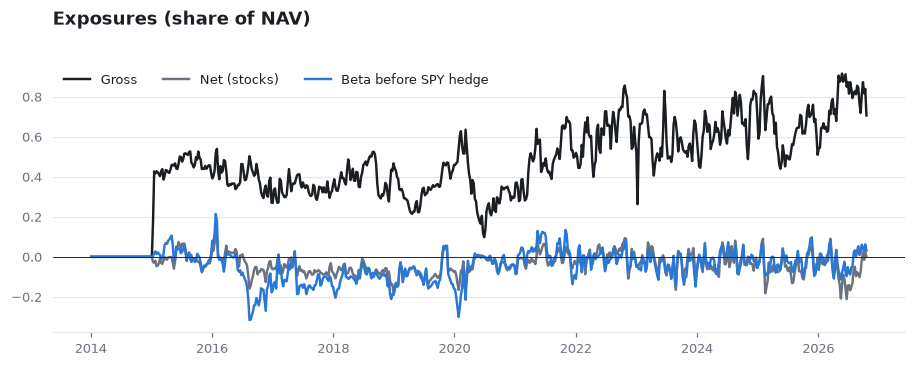

In [2]:
from shiplab import style
expo = pd.read_parquet(R / "exposures.parquet")
style.apply()
fig, ax = plt.subplots(figsize=(10, 3.2))
e = expo.resample("W").mean()
ax.plot(e.index, e["gross"], color=style.INK, label="Gross")
ax.plot(e.index, e["net"], color=style.MUTED, label="Net (stocks)")
ax.plot(e.index, e["beta_before_hedge"], color=style.SEGMENT_COLORS["tankers"], label="Beta before SPY hedge")
ax.axhline(0, color=style.INK, lw=0.6); ax.legend(ncol=3, loc="upper left"); ax.set_title("Exposures (share of NAV)")
plt.show()

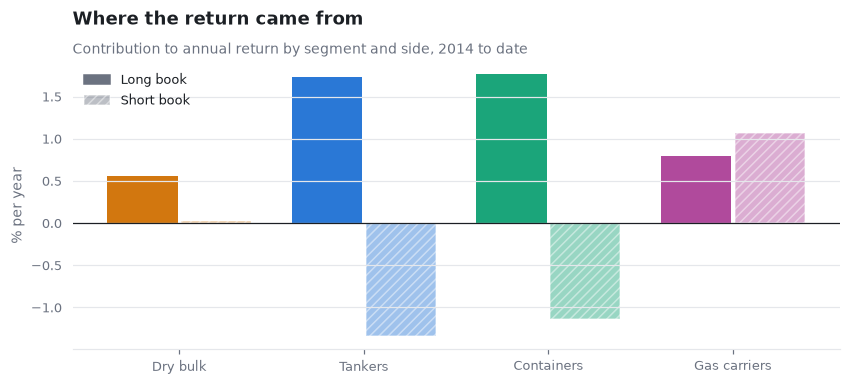

,dry_bulk|long,dry_bulk|short,tankers|long,tankers|short,containers|long,containers|short,gas|long,gas|short,hedge|SPY
contribution per year,0.006,2.000e-04,0.017,-0.013,0.018,-0.011,0.008,0.011,0.004


In [3]:
att = pd.read_parquet(R / "attribution.parquet")
fig = charts.attribution_bars(att, len(att) / 252); charts.save(fig, "07_attribution"); plt.show()
(att.sum() / (len(att) / 252)).rename("contribution per year").to_frame().T.round(4)